# Inner Strength (Templar)

Inner Strength is an upgraded Warcry with a self buff. The Templar gains a large **Weapon Skill**
bonus for 90 s, and every hostile within 10 tiles that fails the Warcry check is stunned for 3 s
and loses 15 from every attribute for 60 s. It costs 200 endurance and has a 30 s cooldown.

| | |
|---|---|
| Class | Templar |
| Target | Self (buff) + the 21×21 square around the caster (Warcry) |
| Cost | 200 endurance, spent first |
| Cooldown | 30 s (separate `SK_INNER_STRENGTH` marker) |
| Landing roll | buff: none. Warcry: deterministic `power >= effective_resist(Resist)` |
| Duration | buff 90 s; War-Stun 3 s; Warcry debuff 60 s |
| Effect | `skill[SK_WEAPON][1] += bonus` on the caster; War-Stun + Warcry on each affected target |
| Source | `server/src/driver/skill/templar.rs::skill_inner_strength`, `warcry`; fight skill in `server/src/state/combat.rs::get_fight_skill` |

---

# Formula

$$
\text{bonus} = \operatorname{clamp}\!\left(3\left(\lfloor p/5 \rfloor + 2\right),\ 3,\ 150\right)
$$

Weapon Skill is the fight skill used for **both attack and defence**, so the bonus adds to the
Templar's $\Delta$ against every enemy and subtracts from every enemy's $\Delta$ against the
Templar. Selected rows of the melee hit table:

| $\Delta$ | −41 or less | −40 | −30 | −20 | 0 | +20 | +30 | +40 or more |
|---|---|---|---|---|---|---|---|---|
| hit on d20 ≤ | 1 | 2 | 4 | 7 | 12 | 18 | 19 | 19 |
| damage bonus | −16 / −32 / −64 | −8 | −2 | 0 | 0 | +3 | +5 | +20 |

The Warcry part is identical to Thunderous Fury without the damage blast.

| Quantity | Breakpoint |
|---|---|
| Bonus at the raise caps | +69 at 105, +78 at 120 |
| Ceiling | +150 at $p \ge 240$ |
| Uptime | 100%: the 90 s buff outlasts the 30 s cooldown, and an equal-power recast refreshes it |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BUFF_S = 90
COOLDOWN_S = 30
END_COST = 200

# Model

In [2]:
def inner_bonus(p):
    return mm.clamp((mm.idiv(p, 5) + 2) * 3, 3, 150)


def hit_chances(p, templar_ws=100, enemy_ws=100):
    """(Templar hit chance, enemy hit chance) while the buff is up."""
    me = templar_ws + inner_bonus(p)
    return mm.p_melee_hit(me - enemy_ws), mm.p_melee_hit(enemy_ws - me)


def damage_per_swing(delta, wv=40, strength=80, armor=20):
    """Expected HP per swing from normal hits: P(hit) × damage with the table bonus."""
    chance, bonus = mm.melee_hit_table(int(delta))
    return chance / 20 * mm.melee_hit_hp(wv, strength, armor, bonus)


def swing_gain(p, enemy_adv=0, **kw):
    """Templar damage per swing with the buff / without it, against an enemy `enemy_adv` ahead."""
    base = damage_per_swing(-enemy_adv, **kw)
    return np.array([damage_per_swing(int(inner_bonus(x)) - enemy_adv, **kw) / base for x in np.atleast_1d(p)])

# Validation

`inner_strength_spends_endurance_and_shakes_nearby_foes`: skill 50 → `a_end` 300,000 → 100,000,
the adjacent target gets War-Stun, the buff is `skill[SK_WEAPON][1] == 36` for `TICKS*90`, and the
cooldown is a separate item lasting `TICKS*30`.
`endurance_skills_do_nothing_without_enough_endurance`: 74,000 endurance is refused.

In [3]:
assert 300_000 - END_COST * 1000 == 100_000 and 74_000 < END_COST * 1000
assert inner_bonus(50) == 36
assert mm.TICKS * BUFF_S == 3240 and mm.TICKS * COOLDOWN_S == 1080
assert inner_bonus(105) == 69 and inner_bonus(120) == 78
assert inner_bonus(239) == 147 and inner_bonus(240) == 150 and inner_bonus(0) == 6
print("Inner Strength model OK")

Inner Strength model OK


# Plots

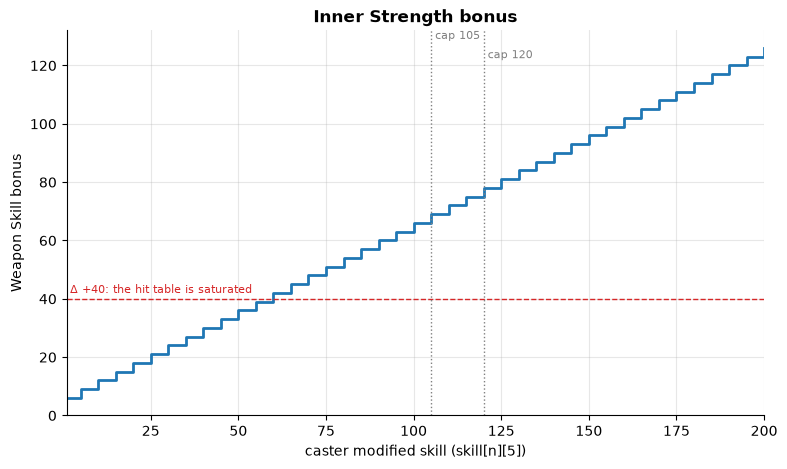

In [4]:
fig, ax = plt.subplots()
ax.step(P, inner_bonus(P), where="post")
ax.axhline(40, color="tab:red", ls="--", lw=1)
ax.text(2, 42, "Δ +40: the hit table is saturated", fontsize=8, color="tab:red")
mm.skill_axis(ax, "Weapon Skill bonus", "Inner Strength bonus")
mm.mark_caps(ax)

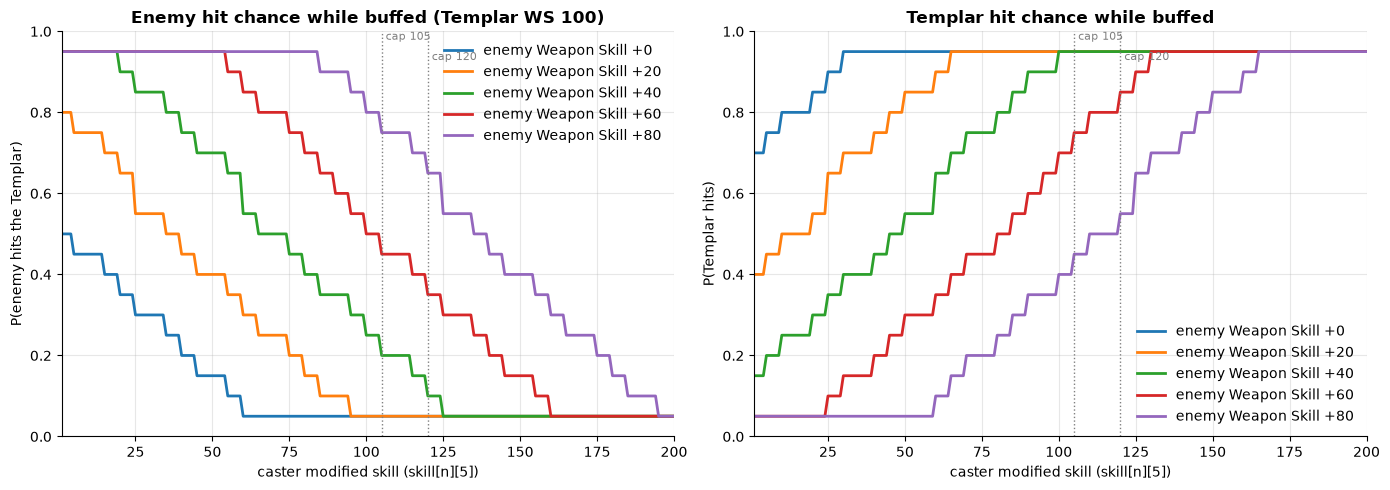

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
advantages = (0, 20, 40, 60, 80)

ax = axes[0]
for adv in advantages:
    _, enemy = hit_chances(P, 100, 100 + adv)
    ax.plot(P, enemy, label=f"enemy Weapon Skill +{adv}")
mm.skill_axis(ax, "P(enemy hits the Templar)", "Enemy hit chance while buffed (Templar WS 100)")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for adv in advantages:
    me, _ = hit_chances(P, 100, 100 + adv)
    ax.plot(P, me, label=f"enemy Weapon Skill +{adv}")
mm.skill_axis(ax, "P(Templar hits)", "Templar hit chance while buffed")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

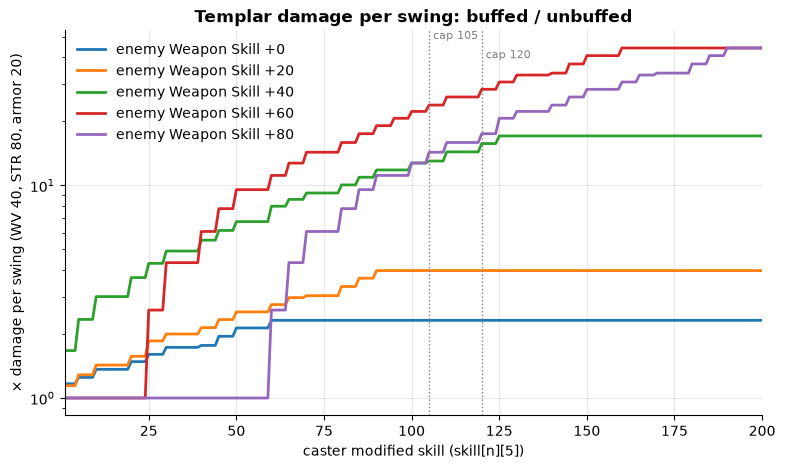

In [6]:
fig, ax = plt.subplots()
for adv in advantages:
    ax.plot(P, swing_gain(P, adv), label=f"enemy Weapon Skill +{adv}")
mm.skill_axis(ax, "× damage per swing (WV 40, STR 80, armor 20)", "Templar damage per swing: buffed / unbuffed")
ax.set_yscale("log")
mm.mark_caps(ax)
ax.legend()

# Observations

- **The same saturation problem as Disarm, on a self buff.** The bonus reaches +42 at skill 60,
  which already pins the hit table against an equal opponent. At skill 105 (+69) an even fight goes
  from 60/60 to 95% for the Templar and 5% for the enemy. The Templar's damage per swing rises
  ×2.3 (6.45 → 15.0 HP at WV 40, STR 80, armor 20), from both the extra hits and the +20 table bonus.
- **Even much stronger enemies are neutralised.** Against an enemy with +40 Weapon Skill the
  skill-105 Templar hits 95% and is hit 20% (unbuffed: 30% / 90%). Against +60 it is 75% / 45%.
  Damage per swing against those enemies rises ×13 and ×24, because the unbuffed Templar was
  landing almost nothing with a negative table bonus.
- **100% uptime for 200 endurance per 30 s at most.** The 90 s buff outlasts the 30 s cooldown,
  and `add_spell` replaces a same-temp spell with an equal-power one, so recasting every 30–90 s
  keeps it up. Recasting only when it expires costs 200 endurance per 90 s.
- **It stacks with Sun's Blessing.** The temps differ (`SK_INNER_STRENGTH2`, `SK_SUNS_BLESSING2`),
  so the +21 Weapon Skill from Sun's Blessing at skill 105 adds on top, for +90 in total.
- **The AoE Warcry comes free.** Every cast also stuns and weakens everything within 10 tiles that
  has Resist ≤ skill, with the same deterministic gate as Thunderous Fury. A refused buff (NoMagic
  tile, full spell slots) spends the endurance but skips the Warcry and the cooldown.
- **Balance suggestions.** Use a much flatter curve, for example `clamp(p/5, 3, 30)` (+21 at 105).
  That keeps Inner Strength meaningful against stronger opponents without pinning the hit table
  against equal ones. Alternatively, shorten the buff below the cooldown (for example 20 s buff,
  30 s cooldown).